In [1]:
import pandas as pd 
import numpy as np
import tensorflow as tf 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Flatten

In [2]:
df_train = pd.read_csv('cifar10/train.csv') 
df_test = pd.read_csv('cifar10/test.csv')

In [3]:
df_train.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [4]:
print(df_train.columns)

Index(['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5',
       'pixel_6', 'pixel_7', 'pixel_8', 'pixel_9',
       ...
       'pixel_3063', 'pixel_3064', 'pixel_3065', 'pixel_3066', 'pixel_3067',
       'pixel_3068', 'pixel_3069', 'pixel_3070', 'pixel_3071', 'label'],
      dtype='object', length=3073)


In [5]:
df_test.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3062,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071
0,158,159,165,166,160,156,162,159,158,159,...,130,123,145,167,182,175,145,124,129,110
1,235,231,232,232,232,232,232,232,232,232,...,108,117,123,133,141,153,163,178,191,199
2,158,158,139,132,166,182,187,193,199,205,...,45,46,44,44,43,52,37,8,3,7
3,155,167,176,190,177,166,168,166,170,179,...,52,55,70,103,105,72,53,50,52,50
4,65,70,48,30,23,40,44,45,45,40,...,102,127,156,139,131,130,147,136,146,117


In [6]:
df_train = df_train.dropna()

In [7]:
X_train = df_train.drop("label", axis = 1).values 
y_train = df_train["label"].values.astype(int)

In [8]:
X_test = df_test.fillna(0).values

In [9]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [10]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)

(50000, 3072)
(50000,)
(10000, 3072)


In [11]:
model = Sequential([   
    Input(shape = (3072,)), 
    Dense(128, activation="relu"),   
    Dense(64, activation="relu"),  
    Dense(10, activation="softmax") ])

In [12]:
model.compile(    optimizer = "adam",   
                  loss = "sparse_categorical_crossentropy",  
                  metrics = ["accuracy"] ) 
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         393,344 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 402,250 (1.53 MB)

 Trainable params: 402,250 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(X_train, y_train, epochs = 20, batch_size = 32, validation_split = 0.2)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.3031 - loss: 1.9131 - val_accuracy: 0.3525 - val_loss: 1.7950
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3771 - loss: 1.7294 - val_accuracy: 0.3742 - val_loss: 1.7357
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4071 - loss: 1.6501 - val_accuracy: 0.4076 - val_loss: 1.6654
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4268 - loss: 1.6053 - val_accuracy: 0.4297 - val_loss: 1.6043
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4354 - loss: 1.5752 - val_accuracy: 0.4339 - val_loss: 1.6035
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.4493 - loss: 1.5418 - val_accuracy: 0.4415 - val_loss: 1.5793
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4574 - loss: 1.5201 - val_accuracy: 0.4274 - val_loss: 1.6089
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4647 - loss: 1.5042 - 

In [14]:
print("Training Accuracy:", history.history['accuracy'][-1])

Training Accuracy: 0.5027499794960022


In [15]:
print("Validation Accuracy:", history.history['val_accuracy'][-1])

Validation Accuracy: 0.45890000462532043


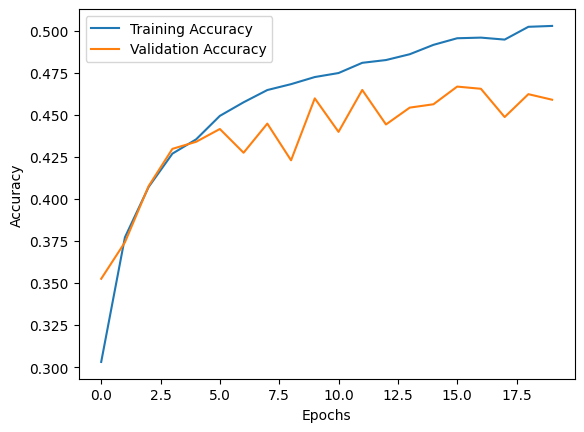

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

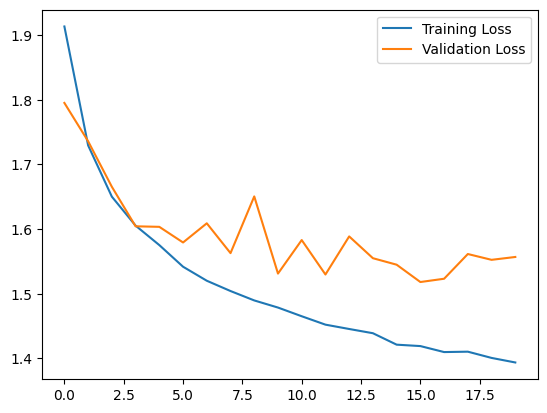

In [17]:
plt.plot(history.history['loss'], label="Training Loss")

plt.plot(history.history['val_loss'], label="Validation Loss")
plt.legend()
plt.show()

In [19]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

# Predict first 10 test images
predictions = model.predict(x_test[:10])
predicted_labels = np.argmax(predictions, axis=1)

# Display images with predicted and actual labels
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(
        f"Predicted: {predicted_labels[i]}\nActual: {y_test[i]}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

NameError: name 'x_test' is not defined